In [1]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

In [2]:
# Load MNIST
(x_train, _), (x_test, _) = mnist.load_data()

# Normalise pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images
x_train = x_train.reshape((x_train.shape[0], -1))
x_test = x_test.reshape((x_test.shape[0], -1))

# Set input and encoding sizes
input_dim = x_train.shape[1]
encoding_dim = 64

In [3]:
# Encoder
input_layer = Input(shape=(input_dim,))
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(encoding_dim, activation="relu")(encoded)

# Decoder
decoded = Dense(128, activation="relu")(encoded)
decoded = Dense(input_dim, activation="sigmoid")(decoded)

# Build autoencoder and encoder models
autoencoder = Model(input_layer, decoded)
encoder = Model(input_layer, encoded)

# Compile and train
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2215 - val_loss: 0.1417
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1247 - val_loss: 0.1106
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1068 - val_loss: 0.1010
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0992 - val_loss: 0.0950
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0940 - val_loss: 0.0908
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0909 - val_loss: 0.0885
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0886 - val_loss: 0.0867
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0867 - val_loss: 0.0849
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0850 - val_loss: 0.0833
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0837 - val_loss: 0.0823
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0826 - val_loss: 0.0811
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

In [4]:
# Show original and reconstructed images
def visualize_reconstruction(autoencoder, x_test, n=10):
    decoded_imgs = autoencoder.predict(x_test[:n])
    plt.figure(figsize=(20, 4))

    for i in range(n):
        # Original image
        plt.subplot(2, n, i + 1)
        plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
        plt.title("Original")
        plt.axis("off")

        # Reconstructed image
        plt.subplot(2, n, i + 1 + n)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


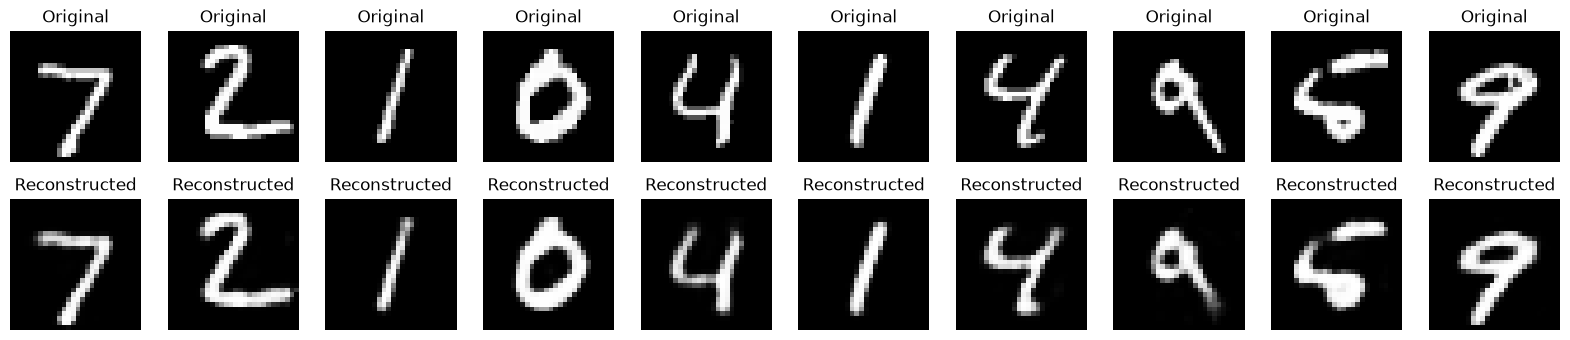

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 756us/step
Shape of encoded data: (10000, 64)


In [5]:
# Visualise reconstructions
visualize_reconstruction(autoencoder, x_test)

# Encode test data
encoded_data = encoder.predict(x_test)

print(f"Shape of encoded data: {encoded_data.shape}")